# Lab 1 · Làm quen Colab & quy trình làm việc với AI

**Lập trình xử lý dữ liệu (LTXLDL) · 2627-1 · Giờ thực hành**  

Giữ bài làm trong notebook này. Với Colab: **File → Save a copy in Drive** trước khi sửa.
Khi chuyển sang GitHub, nộp đúng file `lab-01.ipynb`; lưu trên Drive chưa phải nộp bài.

## Mục tiêu

1. Chạy, sửa, lưu notebook và tái lập kết quả từ kernel sạch.
2. Giải thích trạng thái biến và thứ tự chạy cell.
3. Đọc bảng, tỷ lệ và biểu đồ trên dữ liệu Airbnb.
4. Thực hiện quy trình: tự phác → hỏi → đọc hiểu → kiểm chứng → khai báo.

## Cách làm việc

- Khởi động và bài có hướng dẫn: tự gõ, **không dùng AI**, theo chính sách môn học.
- Phần **Bài tự làm ✅ mở**: được dùng AI, phải ghi prompt, điều đã kiểm chứng và giới hạn.
- Điền cell **Bài làm** và **Trả lời**. Giữ tên hàm/biến, mã câu và các cell công khai đã cho.
- Public checks chỉ cho biết ví dụ nhỏ đã qua. Grader sẽ dùng dữ liệu khác cùng yêu cầu công khai.
- Cell chưa làm được báo `CHƯA LÀM`; một public check lỗi không dừng các check khác.
  Cơ chế này không che lỗi cú pháp ở cell bài làm: bạn vẫn cần sửa lỗi cú pháp để Run all được.
- **Restart & Run all** trước khi nộp. Việc notebook chạy hết với TODO chưa hoàn thành không có nghĩa bài đã đạt.

## Rubric dự kiến — 100 điểm

| Mục | Điểm | Cách đánh giá |
|---|---:|---|
| Q1: thông tin và dự đoán trạng thái | 15 | Tự động |
| Q2: đọc kết quả bảng hiện tại | 10 | Tự động |
| Q3: tỷ lệ theo loại phòng | 15 | Tự động |
| Giải thích trạng thái và khả năng tái lập | 20 | Giảng viên |
| Diễn giải số liệu, phạm vi kết luận | 15 | Giảng viên |
| Quy trình AI và bài tự chọn | 25 | Giảng viên |

Điểm được tính theo từng mục, không theo số lượng public checks. Phần diễn giải do giảng viên đọc.
Các câu độc lập dự kiến được chấm với đầu vào riêng; không trừ toàn bộ lab vì một hàm trước đó sai.


In [1]:
# Public checks giúp tự kiểm tra; đây không phải điểm chính thức.
# Không sửa cell này trong bài nộp.
PUBLIC_RESULTS = {}

def public_check(case_id, check):
    try:
        check()
    except NotImplementedError:
        status, detail = "CHƯA LÀM", "Điền phần TODO rồi chạy lại."
    except AssertionError as exc:
        status, detail = "CHƯA ĐẠT", str(exc) or "Kết quả chưa khớp ví dụ công khai."
    except Exception as exc:
        status, detail = "LỖI", f"{type(exc).__name__}: {exc}"
    else:
        status, detail = "ĐẠT", "Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric."
    PUBLIC_RESULTS[case_id] = status
    print(f"[{status}] {case_id}: {detail}")

def require_answer(value):
    if value is None or value is Ellipsis:
        raise NotImplementedError

def preview(label, action):
    try:
        value = action()
    except NotImplementedError:
        print(f"{label}: chưa chạy được vì còn TODO.")
    except Exception as exc:
        print(f"{label}: {type(exc).__name__}: {exc}")
    else:
        print(label)
        print(value)

def show_public_summary():
    print("PUBLIC CHECKS — không phải điểm chính thức")
    for case_id, status in PUBLIC_RESULTS.items():
        print(f"{case_id}: {status}")
    print("Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.")


## Phần 0 · Khởi động — khoảng 10 phút

Chạy cell bên dưới bằng Shift+Enter. Sửa lời chào, chạy lại và lưu bản sao.
Chưa cần biết pandas hay tự viết hàm ở lab này.


In [2]:
loi_chao = "Xin chào lớp hihi"
print(loi_chao)


Xin chào lớp hihi


## Phần 1 · Trạng thái notebook — khoảng 20 phút

**Thí nghiệm A:** Restart session, sau đó thử chạy cell B trước cell A để quan sát `NameError`.
Sau khi quan sát, chạy A rồi B. Lỗi cố ý này chỉ dùng để học; thứ tự lưu trong file vẫn là A → B.


In [3]:
so_phong_gia_dinh = 4  # Cell A


In [4]:
print("Số phòng:", so_phong_gia_dinh)  # Cell B


Số phòng: 4


**Thí nghiệm B:** chạy cell khởi tạo một lần, cell tăng ba lần. Quan sát giá trị.
Sau đó Restart & Run all: cell tăng chỉ chạy một lần. Hai cách chạy khác nhau nên cho kết quả khác nhau.
Câu Q1 hỏi rõ cả hai cách chạy, không so sánh dự đoán với trạng thái ngẫu nhiên còn trong kernel.


In [5]:
dem = 0  # Khởi tạo


In [6]:
dem += 1
print("dem =", dem)


dem = 1


### Q1 · Thông tin và hai dự đoán — 15 điểm

Điền `ten_cua_ban` là chuỗi có ít nhất 2 ký tự sau khi bỏ khoảng trắng đầu/cuối.
`du_doan_3_lan`: giá trị sau khi khởi tạo 0 và tăng 1 đúng ba lần.
`du_doan_run_all`: giá trị khi Restart & Run all với mỗi cell chạy đúng một lần.
Hai dự đoán phải là số nguyên. Được điền số trực tiếp vì mục tiêu ở đây là dự đoán trạng thái.


In [7]:
ten_cua_ban = "Quỳnh Chi"
du_doan_3_lan = 3
du_doan_run_all = 1


In [8]:
def check_q1_1():
    require_answer(ten_cua_ban)
    assert isinstance(ten_cua_ban, str) and len(ten_cua_ban.strip()) >= 2, "Kiểm tra tên đã điền."

public_check("Q1 · ví dụ 1", check_q1_1)


[ĐẠT] Q1 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [9]:
def check_q1_2():
    require_answer(du_doan_3_lan)
    require_answer(du_doan_run_all)
    assert type(du_doan_3_lan) is int and type(du_doan_run_all) is int
    assert du_doan_3_lan == 3 and du_doan_run_all == 1, "Đối chiếu số lần thực sự chạy cell tăng."

public_check("Q1 · ví dụ 2", check_q1_2)


[ĐẠT] Q1 · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


### Giải thích trạng thái — 20 điểm

Trong 3–5 câu: vì sao B có thể báo `NameError`; vì sao hai cách chạy bộ đếm cho kết quả khác nhau;
và vì sao một notebook chạy được trong phiên hiện tại vẫn có thể lỗi sau restart?
Nêu một thao tác kiểm chứng bạn đã thực hiện. Không cần ảnh chụp màn hình.


**Trả lời của tôi:**

B có thể báo NameError nếu chạy cell tăng dem trước khi chạy cell khởi tạo biến dem = 0, vì lúc đó biến dem chưa tồn tại. Theo cách 1, sau mỗi lần chạy dem tăng thêm 1 và biến giữ trạng thái sau mỗi lần chạy. Còn theo cách 2, khi restart run all, kernel được khởi động lại nên dem trở lại = 0, cell chạy theo thứ tự nên dem = 1. Em đã kiểm chứng bằng cách chạy cell thứ hai 3 lần rồi restart run all.


## Dữ liệu: thử nhanh và thực hành trên snapshot thật

**Bản nháp mở sẵn bằng 6 dòng giả lập**, chứa giá thiếu và giá bằng 0 để thử quy tắc xử lý.
Không dùng kết quả từ 6 dòng này để kết luận về Santiago.

Khi thực hành trên dữ liệu thật, lấy `listings.csv` bản **visualisations**, Santiago,
snapshot **2026-06-29**, giá **CLP/đêm**, từ [Inside Airbnb](https://data.insideairbnb.com/chile/rm/santiago/2026-06-29/visualisations/listings.csv),
hoặc bản sao cùng snapshot do giảng viên cung cấp. Đưa file vào Colab/Jupyter rồi điền
`LISTINGS_PATH` trong cell dưới. Nếu nguồn tải không hoạt động, không thay bằng snapshot khác
mà không ghi rõ. Đường dẫn là cấu hình dữ liệu thực hành, không phải câu trả lời.

Public checks dùng các bộ dữ liệu nhỏ riêng, nên vẫn chạy được khi chưa có snapshot thật.
Các con số của snapshot gốc không được dùng làm hằng số trong lời giải.


In [10]:
from pathlib import Path
import csv
import io

# Nếu đã có snapshot thật, điền đường dẫn, ví dụ "data/listings.csv".
# Để None khi xem bản nháp: dùng 6 dòng GIẢ LẬP ở dưới, không phải Santiago.
LISTINGS_PATH = None
DEMO_CSV = 'id,name,neighbourhood,room_type,price,number_of_reviews,last_review\n1,Phong A,Centro,Entire home/apt,100,0,\n2,Phong B,Centro,Private room,50,2,2026-05-10\n3,Phong C,Norte,Entire home/apt,,0,\n4,Phong D,Norte,Entire home/apt,150,1,2026-06-01\n5,Phong E,Sur,Private room,0,3,2026-05-30\n6,Phong F,Sur,Entire home/apt,300,2,2026-06-10\n'

if LISTINGS_PATH is None:
    rows = list(csv.DictReader(io.StringIO(DEMO_CSV)))
    DATA_LABEL = "GIẢ LẬP — 6 dòng để thử bản nháp"
else:
    with open(LISTINGS_PATH, encoding="utf-8", newline="") as f:
        rows = list(csv.DictReader(f))
    DATA_LABEL = f"File người học cung cấp: {LISTINGS_PATH}"

print(DATA_LABEL)
print("Số dòng:", len(rows))
print(rows[:2])


GIẢ LẬP — 6 dòng để thử bản nháp
Số dòng: 6
[{'id': '1', 'name': 'Phong A', 'neighbourhood': 'Centro', 'room_type': 'Entire home/apt', 'price': '100', 'number_of_reviews': '0', 'last_review': ''}, {'id': '2', 'name': 'Phong B', 'neighbourhood': 'Centro', 'room_type': 'Private room', 'price': '50', 'number_of_reviews': '2', 'last_review': '2026-05-10'}]


Kích thước: (6, 7)
room_type
Entire home/apt    4
Private room       2
Name: count, dtype: int64


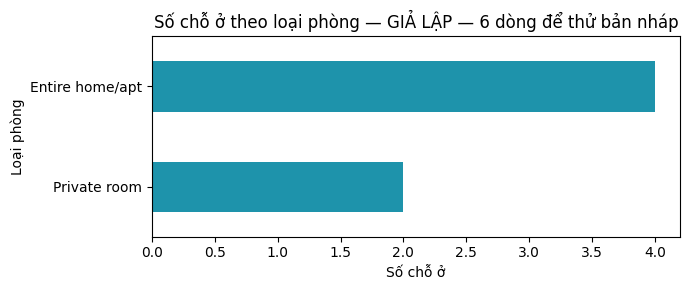

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

ds = pd.DataFrame(rows)
dem_loai = ds["room_type"].value_counts()
print("Kích thước:", ds.shape)
print(dem_loai)
fig, ax = plt.subplots(figsize=(7, 3))
dem_loai.sort_values().plot.barh(ax=ax, color="#1E93AB")
ax.set_title("Số chỗ ở theo loại phòng — " + DATA_LABEL)
ax.set_xlabel("Số chỗ ở")
ax.set_ylabel("Loại phòng")
fig.tight_layout()
plt.show()


### Q2 · Đọc bảng đang sử dụng — 10 điểm

Chạy phần phân tích rồi điền `so_dong` (số nguyên) và `loai_nhieu_nhat` (chuỗi).
Được đọc và điền kết quả ở câu này. Nếu nhiều loại đồng hạng cao nhất, chọn một loại bất kỳ trong số đó.
Khi chuyển từ dữ liệu giả lập sang snapshot thật, đọc lại bảng và cập nhật câu trả lời.


In [12]:
so_dong = 6             # TODO: đọc ds.shape
loai_nhieu_nhat = "Entire home/apt"      # TODO: đọc dem_loai


In [13]:
def check_q2_1():
    require_answer(so_dong)
    assert type(so_dong) is int and so_dong == len(ds), "Đọc số dòng, không lấy số cột."

public_check("Q2 · ví dụ 1", check_q2_1)


[ĐẠT] Q2 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [14]:
def check_q2_2():
    require_answer(loai_nhieu_nhat)
    assert loai_nhieu_nhat in dem_loai.index
    assert dem_loai[loai_nhieu_nhat] == dem_loai.max()

public_check("Q2 · ví dụ 2", check_q2_2)


[ĐẠT] Q2 · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


## Phần 3 · Một vòng làm việc với AI ✅ mở — khoảng 25 phút

Nhiệm vụ: tính phần trăm mỗi loại phòng trong bảng đang dùng, làm tròn một chữ số.
Trước khi hỏi AI, lấy số lượng của một loại chia tổng số dòng để ước lượng bằng tay.
Bạn có thể hỏi AI cách làm từ `dem_loai`, nhưng phải đọc hiểu code và kiểm chứng lại.


### Tự phác trước khi hỏi

Ghi loại phòng, tử số, mẫu số và tỷ lệ ước lượng. Sau khi có code, đối chiếu ước lượng với kết quả.


**Trả lời của tôi:**

Loại phòng: Entire home/apt
Tử số: 4
Loại phòng: Private room
Tử số: 2
Mẫu số: 6
Tỷ lệ ước lượng Private room/apt: 0.67


### Q3 · Tính tỷ lệ bằng code — 15 điểm

Tạo Series `ty_le`, index là các loại phòng có trong `dem_loai`, giá trị là **phần trăm 0–100**,
làm tròn 1 chữ số. Không điền một Series số liệu cố định.
Code phải tính từ `dem_loai` khi bảng đầu vào thay đổi; dữ liệu chấm câu này có ít nhất một dòng,
không thiếu `room_type`. Grader dự kiến thay đầu vào trước khi chạy riêng cell bài làm.


In [15]:
ty_le = (dem_loai/dem_loai.sum()*100).round(1)  # TODO: thay bằng biểu thức pandas tính từ dem_loai
print(ty_le)


room_type
Entire home/apt    66.7
Private room       33.3
Name: count, dtype: float64


In [16]:
def check_q3_1():
    require_answer(ty_le)
    assert isinstance(ty_le, pd.Series), "Kết quả cần là Series."
    expected = (dem_loai / dem_loai.sum() * 100).round(1)
    pd.testing.assert_series_equal(ty_le.sort_index(), expected.sort_index(), check_names=False, check_dtype=False)

public_check("Q3 · ví dụ 1", check_q3_1)


[ĐẠT] Q3 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


### Diễn giải — 15 điểm

Viết 3–5 câu: loại nào chiếm tỷ trọng lớn nhất trong **bảng bạn đang dùng**, bằng chứng là gì?
Vì sao tỷ trọng chỗ ở niêm yết không đồng nghĩa với tỷ trọng lượt đặt phòng?
Nếu đang dùng bộ giả lập, ghi rõ không thể suy rộng kết quả sang Santiago.


**Trả lời của tôi:**

Trong bảng đang dùng, loại Entire home/apt chiếm tỷ trọng lớn nhất, với tỷ lệ 66.7%. Tuy nhiên, tỷ trọng chỗ ở niêm yết chỉ thể hiện số lượng phòng có sẵn trên thị trường chứ không phản ánh tỷ trọng lượt đặt phòng thực tế. Một phòng niêm yết có thể bị bỏ trống hoặc có tỷ lệ đã được đặt thấp hơn so với loại phòng khác. Do đó, vì đang dùng bộ giả lập, kết quả không thể suy rộng cho toàn bộ thị trường Santiago.


## Bài tự làm ✅ mở — cùng khai báo AI chiếm 25 điểm

Chọn một câu hỏi khác trên bảng (ví dụ quận nào có nhiều chỗ ở nhất). Nộp:
**câu hỏi → dự đoán → code → kết quả → kiểm chứng và giới hạn**.
Điền hàm E1 bên dưới để tạo kết quả; ghi giải thích bằng Markdown. Khai báo prompt ở cuối notebook.

Giảng viên chấm dự đoán trước khi hỏi (5), đọc hiểu/code và kết quả (5), kiểm chứng có bằng chứng (10),
khai báo trung thực và giới hạn (5). Không bắt buộc AI phải mắc lỗi; nếu chưa thấy lỗi, nói rõ đã kiểm gì.

**Tự làm thêm, không tính điểm bản nháp:** cài Python và VS Code trên máy, tạo venv và ghi phiên bản Python.


**Trả lời của tôi:**

[Điền câu trả lời, số liệu hoặc bằng chứng ở đây.]


### E1 · Câu hỏi tự chọn: đóng gói kết quả phân tích

Chọn câu hỏi khác Q3 trên bảng đang dùng, ví dụ **quận nào có nhiều chỗ ở nhất**.
Giảng viên đã cho phần khai báo hàm để bạn chỉ cần điền thân hàm; chưa yêu cầu thiết kế chương trình phức tạp.
Mục này vẫn thuộc 25 điểm bài mở/quy trình AI, không thêm điểm hay thu hẹp câu hỏi vào một đáp án cố định.

**Hàm:** `analyze_question(data: pd.DataFrame) -> dict`.

- `data`: bảng listings đã nạp; có các cột được giới thiệu trong lab. Cột `price`, `number_of_reviews`
  ở dạng chuỗi như CSV; nếu dùng chúng, bạn tự chuyển kiểu. Grader có thể thay các dòng dữ liệu,
  vì vậy phải tính từ tham số `data`, không đọc biến `ds` bên ngoài hoặc tải dữ liệu khác trong hàm.
- Trả dict có **đúng ba khóa**: `question` (chuỗi câu hỏi không rỗng),
  `table` (DataFrame kết quả, ít nhất một cột, tên cột là các chuỗi không rỗng và không trùng),
  `unit` (chuỗi mô tả đơn vị, ví dụ `"chỗ ở"`, `"%"`, `"CLP/đêm"`).
- Bạn chọn schema các cột và ghi rõ ở ô mô tả dưới đây. Kết quả một con số vẫn đóng gói thành bảng 1 dòng.
  Với dữ liệu đầu vào rỗng, trả bảng 0 dòng có cùng các cột đã khai báo.
- Không sửa `data` tại chỗ; không `print`, không vẽ hoặc ghi file trong hàm. Hiển thị kết quả ở cell riêng.
- Public checks chỉ kiểm tra hợp đồng chung và việc không sửa đầu vào. **Chúng không xác nhận kết luận đúng**:
  câu hỏi tự chọn vẫn cần giảng viên đối chiếu phép tính, bằng chứng và giới hạn.

Sau khi chọn câu hỏi, bạn có thể tự tạo bảng vài dòng và tính tay để kiểm tra giá trị của `table`.
Nếu muốn chấm hoàn toàn bằng hidden tests sau này, giảng viên cần chốt loại câu hỏi và schema cụ thể.


In [17]:
def analyze_question(data: pd.DataFrame) -> dict:
    """Trả {"question": str, "table": pd.DataFrame, "unit": str} từ data.

    TODO: mô tả các cột bảng kết quả bạn chọn trong docstring này.
    Không dùng ds toàn cục; không sửa data tại chỗ.
    """
    if data.empty:
      table=pd.DataFrame(columns=["neighbourhood","so_cho_o"])
    else:
      table=(
          data["neighbourhood"]
          .value_counts()
          .reset_index()
      )
      table.columns=["neighbourhood","so_cho_o"]
    return {
        "question": "Quận nào có nhiều chỗ ở nhất",
        "table": table,
        "unit": "chỗ ở"
    }

In [18]:
def check_e1_1():
    sample = pd.DataFrame([
        {"id": "1", "name": "A", "neighbourhood": "X", "room_type": "Private room", "price": "10", "number_of_reviews": "0", "last_review": ""},
        {"id": "2", "name": "B", "neighbourhood": "X", "room_type": "Entire home/apt", "price": "20", "number_of_reviews": "1", "last_review": "2026-01-01"},
        {"id": "3", "name": "C", "neighbourhood": "Y", "room_type": "Private room", "price": "30", "number_of_reviews": "2", "last_review": "2026-01-02"},
    ])
    before = sample.copy(deep=True)
    result = analyze_question(sample)
    assert isinstance(result, dict) and set(result) == {"question", "table", "unit"}
    assert isinstance(result["question"], str) and result["question"].strip()
    assert isinstance(result["unit"], str) and result["unit"].strip()
    table = result["table"]
    assert isinstance(table, pd.DataFrame) and len(table.columns) >= 1
    assert table.columns.is_unique
    assert all(isinstance(c, str) and c.strip() for c in table.columns)
    pd.testing.assert_frame_equal(sample, before)

public_check("E1 · mở rộng · ví dụ 1", check_e1_1)


[ĐẠT] E1 · mở rộng · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [19]:
def check_e1_2():
    sample = pd.DataFrame(rows[:2])
    full = analyze_question(sample)
    empty = analyze_question(sample.iloc[:0].copy())
    assert isinstance(empty, dict) and set(empty) == {"question", "table", "unit"}
    assert isinstance(empty["table"], pd.DataFrame)
    assert empty["table"].empty
    assert list(empty["table"].columns) == list(full["table"].columns)
    assert isinstance(empty["question"], str) and empty["question"].strip()
    assert isinstance(empty["unit"], str) and empty["unit"].strip()

public_check("E1 · mở rộng · ví dụ 2", check_e1_2)


[ĐẠT] E1 · mở rộng · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [20]:
def show_my_analysis():
    result = analyze_question(ds)
    print("Câu hỏi:", result["question"], "| Đơn vị:", result["unit"])
    return result["table"]

preview("Kết quả câu hỏi tự chọn", show_my_analysis)


Câu hỏi: Quận nào có nhiều chỗ ở nhất | Đơn vị: chỗ ở
Kết quả câu hỏi tự chọn
  neighbourhood  so_cho_o
0        Centro         2
1         Norte         2
2           Sur         2


**Mô tả câu hỏi và đầu ra của tôi:**

- Câu hỏi: Quận nào có nhiều chỗ ở nhất?
- Các cột đầu vào được dùng: neighbourhood
- Các cột kết quả:
  Cột 1: neighbourhood -> Tên quận -> str
  Cột 2: so_cho_o -> Số lượng chỗ ở -> int
- Cách xử lý giá trị thiếu nếu câu hỏi có dùng: Hàm value_counts() sẽ tự động bỏ qua các dòng bị thiếu tên quận. Còn nếu truyền vào một bảng rỗng hoàn toàn (data.empty), hàm sẽ chủ động tạo một bảng rỗng có sẵn 2 tiêu đề cột neighbourhood và so_cho_o.
- Ví dụ tôi tính tay và kết quả mong đợi: Mỗi quận đều có 2 chỗ ở
- Dự đoán → kết quả thực tế → kiểm chứng → giới hạn: Mỗi quận đều có 2 chỗ ở -> Mỗi quận đều có 2 chỗ ở -> Đếm bằng tay cũng ra kết quả nhu vậy -> Vì đang chạy giả lập nên con số này không phản ánh đúng thực tế các quận ở Santiago.

Phần mô tả và khai báo AI được giảng viên đọc cùng kết quả hàm.


## Trước khi nộp

1. Điền tên, mã sinh viên và nguồn dữ liệu đã dùng ở cell dưới.
2. Restart & Run all; sửa các lỗi và đọc lại bảng public checks.
3. Hoàn thành câu trả lời diễn giải và khai báo AI, kể cả khi không dùng AI.
4. Giữ tên file và cell bài làm. Không chép kết quả hiển thị thành hằng số thay cho phép xử lý.
5. Khi giảng viên phát hành hướng dẫn nộp chính thức: lưu notebook vào repo cá nhân của môn,
   commit/push và tạo tag theo hướng dẫn của lab. **Bản nháp này chưa nối với grader đang chạy.**


**Họ tên / mã sinh viên:** Lê Quỳnh Chi / 25022800

**Nguồn dữ liệu thực hành:** Giả lập để xem nháp; đường dẫn file

**Khai báo AI cho phần được phép dùng:**

- Công cụ/model, hoặc “Không dùng”: Gemini
- Prompt chính: "Viết hàm pandas đếm số chỗ ở theo từng quận từ cột neighbourhood, trả về dict gồm question, table, unit."
- Tôi đã tự dự đoán gì trước khi hỏi: Tự đếm tay trên 6 dòng giả lập và dự đoán 3 quận Centro, Norte, Sur đều có 2 chỗ ở.
- Kết quả AI cần sửa hoặc điểm tôi chưa chắc: Không có.
- Cách tôi kiểm chứng, kèm ví dụ cụ thể: Chạy các ô public_check để đảm bảo không lỗi, so sánh bảng kết quả với đếm tay trên 6 dòng giả lập.


In [21]:
show_public_summary()


PUBLIC CHECKS — không phải điểm chính thức
Q1 · ví dụ 1: ĐẠT
Q1 · ví dụ 2: ĐẠT
Q2 · ví dụ 1: ĐẠT
Q2 · ví dụ 2: ĐẠT
Q3 · ví dụ 1: ĐẠT
E1 · mở rộng · ví dụ 1: ĐẠT
E1 · mở rộng · ví dụ 2: ĐẠT
Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.
